In [2]:
import os
import sys
from pathlib import Path

import numpy as np
import networkx as nx

import matplotlib.pyplot as plt
import matplotlib as mpl
# import cmasher as cmr

ROOT = Path().cwd().resolve().parents[1]
if str(ROOT) not in sys.path:
    sys.path.append(str(ROOT))

from src.inference import get_posterior_draws
from src.simulation import simple_kernel
from src.analysis import compute_complexity_scores
from scipy.special import logit

/sfs/gpfs/tardis/home/pny2cw/projects/HETKER/heterogeneous-infection-kernels/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
data_dir = Path("results/real/congress/inference_congress_omega_sweep/")

In [4]:
def extract_params(filename: str) -> float:
    return float(os.path.basename(filename).split("_")[1].split("-")[1])

# Prototype

In [4]:
fn_test = data_dir / "np_omega-0.0_rep-0_1191b8fb.npz"

In [5]:
extract_params(fn_test)

0.0

In [6]:
data = np.load(fn_test)
data

NpzFile 'results/real/congress/inference_congress_omega_sweep/np_omega-0.0_rep-0_1191b8fb.npz' with keys: draws_mu

In [7]:
data["draws_mu"]

array([[[0.01616642, 0.03181021, 0.05652326, ..., 0.92710632,
         0.93216712, 0.94257508]],

       [[0.01769507, 0.03533968, 0.05517755, ..., 0.90207619,
         0.90531866, 0.91531414]],

       [[0.01472575, 0.03413423, 0.05510422, ..., 0.88642413,
         0.89132899, 0.92467285]],

       ...,

       [[0.01828437, 0.03742596, 0.04676463, ..., 0.87858431,
         0.87915312, 0.92614342]],

       [[0.01677377, 0.04017735, 0.04668013, ..., 0.92968359,
         0.93306972, 0.93795363]],

       [[0.01258819, 0.03572395, 0.06014963, ..., 0.88461439,
         0.9084187 , 0.91380016]]], shape=(500, 1, 42))

In [8]:
fn_test_simple = data_dir / "simple_omega-0.0_rep-0_1191b8fb.npz"

In [9]:
simple = np.load(fn_test_simple)
simple

NpzFile 'results/real/congress/inference_congress_omega_sweep/simple_omega-0.0_rep-0_1191b8fb.npz' with keys: draws_beta, draws_mu

In [10]:
simple["draws_beta"]

array([[0.02682646],
       [0.02590948],
       [0.02683841],
       [0.02740916],
       [0.02770528],
       [0.02708208],
       [0.02711788],
       [0.02687671],
       [0.02586306],
       [0.02737942],
       [0.02631193],
       [0.02786134],
       [0.02859124],
       [0.02903292],
       [0.02735911],
       [0.02673703],
       [0.02705183],
       [0.02608954],
       [0.02745415],
       [0.02683487],
       [0.02687775],
       [0.02658273],
       [0.02612199],
       [0.02665266],
       [0.02592757],
       [0.02673131],
       [0.02470309],
       [0.02649571],
       [0.02586253],
       [0.02633106],
       [0.0259091 ],
       [0.02762132],
       [0.02620036],
       [0.02536486],
       [0.02583404],
       [0.02551369],
       [0.02671411],
       [0.02605811],
       [0.02707912],
       [0.02715075],
       [0.02315472],
       [0.02478045],
       [0.02518469],
       [0.02387262],
       [0.02417919],
       [0.02536236],
       [0.02644562],
       [0.025

In [11]:
kmax = len(data["draws_mu"][0, 0, :])

In [12]:
ref = logit( simple_kernel(np.mean(simple["draws_beta"]), kmax) )

In [13]:
compute_complexity_scores(data["draws_mu"], ref)

{'mean_distance': 117.65748728431731,
 'erank': 25.854621958563474,
 'complexity': 4.550733229551137,
 'n_draws': 500,
 'kmax': 42}

# Data preprocessing

In [5]:
# NOTE: This exists in the `data_cache`, 
# but since this is one parameter, 
# its honestly quicker to parse the filename

data = dict()

for filename in [_filename for _filename in os.listdir(data_dir) if "simple" not in _filename]:
    kernel = np.load(data_dir / filename)["draws_mu"]

    beta = np.load(data_dir / filename.replace("np", "simple", 1))["draws_beta"].mean()

    omega = extract_params(filename)
    if omega not in data:
        data[omega] = []

    kmax = len(kernel[0, 0, :])
    ref = logit( simple_kernel(beta, kmax) )
    complexity = compute_complexity_scores(kernel, ref)["complexity"]
    
    data[omega].append(complexity)

In [6]:
# data

In [7]:
kernels = dict()

for filename in [_filename for _filename in os.listdir(data_dir) if "simple" not in _filename]:
    kernel = np.load(data_dir / filename)["draws_mu"]

    omega = extract_params(filename)
    if omega not in kernels:
        kernels[omega] = []

    kernels[omega].append(kernel[:, 0, :])

In [8]:
# kernels[0.05]

# Figure

In [9]:
_lowomega = 0.05
_highomega = 0.45

_omegas = sorted(data.keys())

_darkkernel = "#63B4E0"
_lightkernel = "#005B94"

magma = mpl.colormaps['magma'].resampled(10)
_darkcomms = magma(0.2)
_lightcomms = magma(0.5)
# _darkcomms = "#7570b3"
# _lightcomms = "#d95f02"

/sfs/gpfs/tardis/home/pny2cw/projects/HETKER/heterogeneous-infection-kernels/.venv/lib/python3.13/site-packages/networkx/drawing/nx_pylab.py:1497: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  node_collection = ax.scatter(


Text(0.1, 4.8, '(b)')

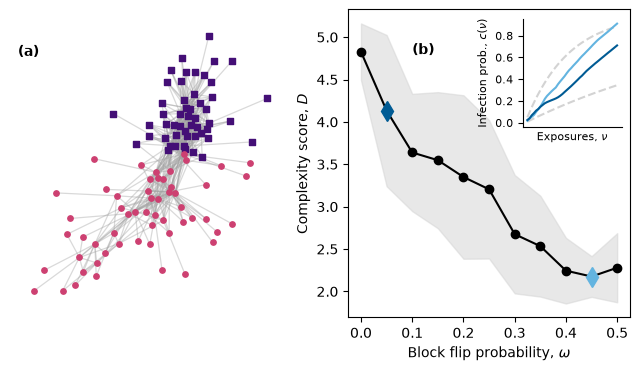

In [33]:
fig, axs = plt.subplots(
    1, 2,
    figsize=(8, 4)
)
plt.xlabel("Block flip probability, "+r"$\omega$")
# plt.ylabel("Complexity score, "+r"$\langle D \rangle$")
plt.ylabel("Complexity score, "+r"$D$")

# --- Primary figure ---
# Complexity as function of omega
plt.fill_between(
    x = _omegas,
    y1 = [np.mean(data[omega])-np.std(data[omega]) for omega in _omegas],
    y2 = [np.mean(data[omega])+np.std(data[omega]) for omega in _omegas],
    color="lightgray",
    alpha=0.5
)
plt.plot(
    _omegas,
    [np.mean(data[omega]) for omega in _omegas],
    color="black",
    marker="o"
)
plt.plot(
    _lowomega,
    np.mean(data[_lowomega]),
    color=_lightkernel,
    marker="d",
    markersize=10
)
plt.plot(
    _highomega,
    np.mean(data[_highomega]),
    color=_darkkernel,
    marker="d",
    markersize=10,
)


# --- Secondary insets ---
# Average kernels at particular omega
axins = axs[1].inset_axes(
    [0.62, 0.62, 0.35, 0.35],
    xticklabels=[],
    yticklabels=[]
)

axins.set_xlabel("Exposures, "+r"$\nu$", fontsize=8)
axins.set_ylabel("Infection prob., "+r"$c(\nu)$", fontsize=8)

_inset_yticks = np.linspace(0, 1, 6)
axins.set_yticks(_inset_yticks, labels=[f"{y:.01f}" for y in _inset_yticks], fontsize=8)

axins.set_xticks([])

axins.spines['right'].set_visible(False)
axins.spines['top'].set_visible(False)

kernel_lowomega = np.mean(kernels[_lowomega][-1], axis=0)
kernel_highomega = np.mean(kernels[_highomega][-1], axis=0)

axins.plot(simple_kernel(0.01, kmax), color="lightgray", linestyle="dashed")
axins.plot(simple_kernel(0.05, kmax), color="lightgray", linestyle="dashed")
axins.plot(kernel_lowomega, color=_darkkernel)
axins.plot(kernel_highomega, color=_lightkernel)

# --- Tertiary inset ---
# Network bisection
# axins_graph = axs.inset_axes(
#     [0.0, 0.00, 0.35, 0.35],
#     xticklabels=[],
#     yticklabels=[]
# )

axins_graph = axs[0]

axins_graph.spines['left'].set_visible(False)
axins_graph.spines['right'].set_visible(False)
axins_graph.spines['top'].set_visible(False)
axins_graph.spines['bottom'].set_visible(False)

axins_graph.patch.set_alpha(0.0)


G = nx.read_edgelist("data/congress/processed/congress.edgelist")
pos = nx.spring_layout(G, seed=37)

_c1 = []
_c2 = []
with open("data/congress/processed/communities.txt") as _fh:
    for node, line in enumerate(_fh.readlines()):
        if int(line.strip()) == 1:
            _c1.append(str(node))
        else:
            _c2.append(str(node))

nx.draw_networkx_nodes(
    G,
    pos=pos,
    ax=axins_graph,
    nodelist=_c1,
    # Node properties
    node_size=15,
    node_color=_darkcomms,
    node_shape="s"
)
nx.draw_networkx_nodes(
    G,
    pos=pos,
    ax=axins_graph,
    nodelist=_c2,
    # Node properties
    node_size=15,
    node_color=_lightcomms,
    node_shape="o"
)
nx.draw_networkx_edges(
    G,
    pos=pos,
    ax=axins_graph,
    # Edge properties
    width=0.9,
    alpha=0.40,
    edge_color='#a1a1a1'
)

axs[0].text(
    -1, 0.85,
    "(a)",
    fontdict={"weight": "bold"}
)
axs[1].text(
    0.1, 4.8,
    "(b)",
    fontdict={"weight": "bold"}
)

# plt.savefig("fig-complexity_congress.pdf")

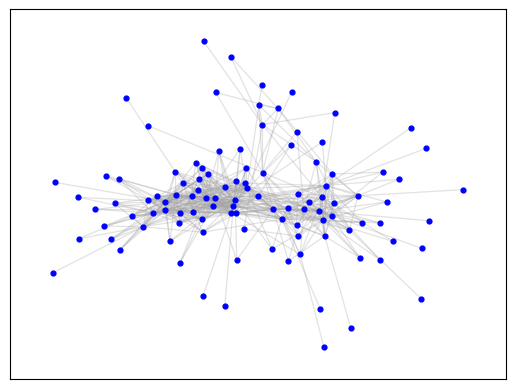

In [13]:
# G = nx.read_edgelist("data/congress/processed/congress.edgelist")
# pos = nx.spring_layout(G)

# _c1 = []
# _c2 = []
# with open("data/congress/processed/communities.txt") as _fh:
#     for node, line in enumerate(_fh.readlines()):
#         if int(line.strip()) == 1:
#             _c1.append(str(node))
#         else:
#             _c2.append(str(node))

# nx.draw_networkx_nodes(
#     G,
#     pos=pos,
#     # ax=axins_graph,
#     # nodelist=_c2,
#     # Node properties
#     node_size=12,
#     node_color="blue", 
#     node_shape="o"
# )
# nx.draw_networkx_edges(
#     G,
#     pos=pos,
#     # ax=axins_graph,
#     # Edge properties
#     width=0.9,
#     alpha=0.30,
#     edge_color='#a1a1a1'
# )

# plt.savefig("fig-congress.svg")